# Stage 4.7 — Final Logistic Freeze + Full-Train Refit

This Notebook records the frozen Human decision to retain all ten predictors, reconstructs the approved Full-Train WOE specification, and refits exactly one final explicit-intercept unpenalized MLE Logistic model on the complete 24,000-row Development Train.

Hard boundaries: no feature deletion, alternative subset, 10-vs-9 comparison, re-binning, cross-validation, OOF generation, regularization, class weighting/resampling, calibration, operational threshold optimization, or Holdout predictive analysis. Stage 5 owns the first predictive application to Holdout.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
sns.set_theme(style="whitegrid", context="notebook")

TARGET = "default.payment.next.month"
ID_COL = "ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20
REPRODUCTION_TOLERANCE = 1e-9
EXPECTED_TRAIN_HASH = "bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857"
EXPECTED_TEST_HASH = "d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"
FINAL_PREDICTORS = [
    "PAY_0", "severe_delinquent_months",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "LIMIT_BAL", "avg_utilization",
]
PAY_VARIABLES = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_VARIABLES = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_VARIABLES = [f"PAY_AMT{i}" for i in range(1, 7)]
assert len(FINAL_PREDICTORS) == len(set(FINAL_PREDICTORS)) == 10

def locate_project_root():
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "data/raw/UCI_Credit_Card.csv").is_file():
            return candidate
    raise FileNotFoundError("Formal raw CSV not found from launch path or its parents.")

def stable_id_hash(values):
    canonical = "\n".join(str(int(value)) for value in sorted(values))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

project_root = locate_project_root()
data_path = project_root / "data/raw/UCI_Credit_Card.csv"
environment_table = pd.DataFrame({"Value": [
    sys.executable, sys.version.split()[0], metadata.version("pandas"), metadata.version("numpy"),
    metadata.version("scipy"), metadata.version("scikit-learn"), metadata.version("matplotlib"),
    metadata.version("seaborn"), metadata.version("statsmodels"),
]}, index=[
    "Python executable", "Python version", "pandas", "numpy", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "statsmodels",
])
display(environment_table)
print("Project root:", project_root)
print("Final frozen predictor order:", FINAL_PREDICTORS)


,Value
Python executable,/opt/anaconda3/bin/python
Python version,3.11.7
pandas,2.1.4
numpy,1.26.4
scipy,1.11.4
scikit-learn,1.2.2
matplotlib,3.8.0
seaborn,0.12.2
statsmodels,0.14.0


Project root: /Users/yu/2.工作/Risk Analysis Project
Final frozen predictor order: ['PAY_0', 'severe_delinquent_months', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'LIMIT_BAL', 'avg_utilization']


## 1. Frozen outer split replay and immediate Holdout sealing

Holdout is used only for row count, ID overlap, ID union coverage, and frozen ID hash. No Holdout predictor values, target distribution, bins, WOE, probabilities, performance, calibration, thresholds, or risk relationships are inspected.


In [2]:
raw_df = pd.read_csv(data_path)
assert raw_df.shape == (30000, 25) and raw_df[ID_COL].is_unique

development_raw, sealed_holdout = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)
development_ids = set(development_raw[ID_COL].astype(int))
holdout_ids = set(sealed_holdout[ID_COL].astype(int))
full_ids = set(raw_df[ID_COL].astype(int))
train_hash = stable_id_hash(development_ids)
test_hash = stable_id_hash(holdout_ids)
id_overlap = len(development_ids & holdout_ids)
id_union_complete = development_ids | holdout_ids == full_ids

assert len(development_raw) == 24000 and len(sealed_holdout) == 6000
assert id_overlap == 0 and id_union_complete
assert train_hash == EXPECTED_TRAIN_HASH and test_hash == EXPECTED_TEST_HASH

outer_split_evidence = pd.DataFrame({"Actual": [
    30000, len(development_raw), len(sealed_holdout), id_overlap, id_union_complete,
    train_hash, test_hash,
]}, index=[
    "Raw rows", "Development Train rows", "Holdout rows", "ID overlap",
    "Full ID union coverage", "Train ID SHA-256", "Test ID SHA-256",
])
display(outer_split_evidence)

del sealed_holdout, holdout_ids, full_ids, raw_df
HOLDOUT_SEAL_STATUS = "SEALED — Holdout deleted after row/ID/union/hash identity checks only; Stage 5 only"
print(HOLDOUT_SEAL_STATUS)

DEVELOPMENT_GOOD = int((development_raw[TARGET] == 0).sum())
DEVELOPMENT_BAD = int((development_raw[TARGET] == 1).sum())
DEVELOPMENT_BAD_RATE = DEVELOPMENT_BAD / len(development_raw)
assert (DEVELOPMENT_GOOD, DEVELOPMENT_BAD) == (18691, 5309)
print(f"Development Train: Good={DEVELOPMENT_GOOD:,}; Bad={DEVELOPMENT_BAD:,}; bad rate={DEVELOPMENT_BAD_RATE:.6%}")


,Actual
Raw rows,30000
Development Train rows,24000
Holdout rows,6000
ID overlap,0
Full ID union coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — Holdout deleted after row/ID/union/hash identity checks only; Stage 5 only
Development Train: Good=18,691; Bad=5,309; bad rate=22.120833%


## 2. Frozen Human final-variable decision and evidence synthesis

The Human final-variable decision is **KEEP ALL 10 PREDICTORS**. It synthesizes Stage 4.4 standalone signal/redundancy/governance screening, Stage 4.5 Full-Train multivariate behavior, Stage 4.6 five-fold coefficient/predictive stability, and business/temporal interpretability. It is not an automatic p-value, confidence-interval, IV, VIF, or coefficient-dispersion rule.


In [3]:
HUMAN_FINAL_DECISION = "KEEP ALL 10 PREDICTORS"
STAGE46_STABILITY = {
    "PAY_0": (5, 5, 0),
    "severe_delinquent_months": (5, 5, 0),
    "PAY_AMT1": (5, 5, 0),
    "PAY_AMT2": (5, 5, 0),
    "PAY_AMT3": (5, 5, 0),
    "PAY_AMT4": (5, 4, 1),
    "PAY_AMT5": (5, 0, 5),
    "PAY_AMT6": (5, 2, 3),
    "LIMIT_BAL": (5, 5, 0),
    "avg_utilization": (5, 5, 0),
}
STAGE45_STATUS = {
    predictor: ("Review in Stage 4.6" if predictor == "PAY_AMT5" else "Directionally Clear")
    for predictor in FINAL_PREDICTORS
}
STRUCTURAL_NOTES = {
    "PAY_0": "Recent/current delinquency status retained as a primary behavioral signal.",
    "severe_delinquent_months": "Historical serious-delinquency persistence complements current status.",
    "PAY_AMT1": "Month-specific payment-history component in the coherent six-month family.",
    "PAY_AMT2": "Month-specific payment-history component in the coherent six-month family.",
    "PAY_AMT3": "Month-specific payment-history component in the coherent six-month family.",
    "PAY_AMT4": "5/5 negative and 4/5 clear; part of the continuum of monthly conditional strength.",
    "PAY_AMT5": "Weaker conditional evidence but 5/5 negative; no defensible month-5 cutoff, so temporal-family coherence supports retention.",
    "PAY_AMT6": "5/5 negative and 2/5 clear; adjacent evidence confirms no clean month-5 cutoff.",
    "LIMIT_BAL": "Distinct credit-capacity signal retained under approved governance screening.",
    "avg_utilization": "Distinct balance-to-limit burden signal; uncapped utilization above one preserved.",
}

evidence_rows = []
for predictor in FINAL_PREDICTORS:
    negative, clear, crosses = STAGE46_STABILITY[predictor]
    evidence_rows.append({
        "Predictor": predictor,
        "Stage 4.4 Decision": "Keep / candidate approved",
        "Stage 4.5 Status": STAGE45_STATUS[predictor],
        "Stage 4.6 Negative Folds / 5": f"{negative}/5",
        "Stage 4.6 Directionally Clear Folds / 5": f"{clear}/5",
        "Stage 4.6 CI-Crosses-Zero Folds / 5": f"{crosses}/5",
        "Structural / Interpretability Note": STRUCTURAL_NOTES[predictor],
        "Stage 4.7 Final Decision": "Retain",
    })
evidence_synthesis = pd.DataFrame(evidence_rows)
assert evidence_synthesis.shape == (10, 8)
assert evidence_synthesis["Predictor"].tolist() == FINAL_PREDICTORS
assert evidence_synthesis["Stage 4.7 Final Decision"].eq("Retain").all()
display(evidence_synthesis)

stage46_context = pd.DataFrame({"Accepted value": [
    0.771230165, 0.429462039, 0.771415388, 0.004852803,
    0.436219472, 0.008255848, 0.001186933, 0.000845828,
]}, index=[
    "Pooled OOF AUC", "Pooled OOF KS", "Mean fold AUC", "Fold AUC sample SD",
    "Mean fold KS", "Fold KS sample SD", "Apparent-minus-OOF AUC gap",
    "Apparent-minus-OOF KS gap",
])
display(stage46_context)
print("PASS — frozen Human decision recorded; all ten retained in canonical order.")


,Predictor,Stage 4.4 Decision,Stage 4.5 Status,Stage 4.6 Negative Folds / 5,Stage 4.6 Directionally Clear Folds / 5,Stage 4.6 CI-Crosses-Zero Folds / 5,Structural / Interpretability Note,Stage 4.7 Final Decision
0,PAY_0,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Recent/current delinquency status retained as ...,Retain
1,severe_delinquent_months,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Historical serious-delinquency persistence com...,Retain
2,PAY_AMT1,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Month-specific payment-history component in th...,Retain
3,PAY_AMT2,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Month-specific payment-history component in th...,Retain
4,PAY_AMT3,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Month-specific payment-history component in th...,Retain
5,PAY_AMT4,Keep / candidate approved,Directionally Clear,5/5,4/5,1/5,5/5 negative and 4/5 clear; part of the contin...,Retain
6,PAY_AMT5,Keep / candidate approved,Review in Stage 4.6,5/5,0/5,5/5,Weaker conditional evidence but 5/5 negative; ...,Retain
7,PAY_AMT6,Keep / candidate approved,Directionally Clear,5/5,2/5,3/5,5/5 negative and 2/5 clear; adjacent evidence ...,Retain
8,LIMIT_BAL,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Distinct credit-capacity signal retained under...,Retain
9,avg_utilization,Keep / candidate approved,Directionally Clear,5/5,5/5,0/5,Distinct balance-to-limit burden signal; uncap...,Retain


,Accepted value
Pooled OOF AUC,0.771230
Pooled OOF KS,0.429462
Mean fold AUC,0.771415
Fold AUC sample SD,0.004853
Mean fold KS,0.436219
Fold KS sample SD,0.008256
Apparent-minus-OOF AUC gap,0.001187
Apparent-minus-OOF KS gap,0.000846


PASS — frozen Human decision recorded; all ten retained in canonical order.


### PAY_AMT5 frozen retention rationale

`PAY_AMT5` has weaker incremental multivariate evidence, not unstable direction. Its Stage 4.5 coefficient was approximately −0.097122437, with a confidence interval crossing zero and p≈0.21635. In Stage 4.6 all five coefficients remained negative (−0.125774, −0.057477, −0.098118, −0.041387, −0.160361), their mean (≈−0.096623) closely reproduced the Full-Train estimate, and all five confidence intervals crossed zero.

It remains because there is no sign instability; Stage 4.4 found no defensible natural month cutoff; PAY_AMT1–6 form a coherent six-month payment-history family; selectively removing only month 5 while retaining months 4 and 6 lacks a defensible temporal/business rationale; and automatic p-value/CI elimination is not the project governance rule. `PAY_AMT4` (5/5 negative, 4/5 Directionally Clear) and `PAY_AMT6` (5/5 negative, 2/5 Directionally Clear) show a continuum of conditional strength rather than a clean cutoff. This does not claim that `PAY_AMT5` is statistically strong or without weakness.

No 10-vs-9 comparison, recent-month-only model, feature aggregation, or alternative subset is fitted.


## 3. Approved feature engineering and frozen bin definitions

Only `severe_delinquent_months = sum(PAY_i >= 2)` and uncapped `avg_utilization = mean(max(BILL_AMT1,0), …, max(BILL_AMT6,0)) / LIMIT_BAL` are reproduced. No new feature is created.


In [4]:
train_work = development_raw.copy(deep=True)
index_before = train_work.index.copy()
ids_before = train_work[ID_COL].copy(deep=True)
target_before = train_work[TARGET].copy(deep=True)
raw_sources = PAY_VARIABLES + BILL_VARIABLES + PAY_AMT_VARIABLES + ["LIMIT_BAL"]
raw_sources_before = train_work[raw_sources].copy(deep=True)

train_work["severe_delinquent_months"] = (train_work[PAY_VARIABLES] >= 2).sum(axis=1).astype("int64")
assert (train_work["LIMIT_BAL"] > 0).all()
positive_bills_for_calculation = train_work[BILL_VARIABLES].clip(lower=0)
train_work["avg_utilization"] = positive_bills_for_calculation.mean(axis=1) / train_work["LIMIT_BAL"]
del positive_bills_for_calculation

assert train_work.index.equals(index_before)
assert train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[raw_sources], raw_sources_before, check_exact=True)
assert train_work[["severe_delinquent_months", "avg_utilization"]].notna().all().all()
assert np.isfinite(train_work["avg_utilization"]).all() and (train_work["avg_utilization"] >= 0).all()
assert (train_work["avg_utilization"] > 1).any()
print("PASS — approved target-independent features reproduced; rows, IDs, targets, and raw sources unchanged.")


PASS — approved target-independent features reproduced; rows, IDs, targets, and raw sources unchanged.


In [5]:
PAY_DOMAIN = set(range(-2, 9))
PAY0_MAP = {
    -2: "[-2,-1,0]", -1: "[-2,-1,0]", 0: "[-2,-1,0]", 1: "[1]",
    2: "[2+]", 3: "[2+]", 4: "[2+]", 5: "[2+]", 6: "[2+]", 7: "[2+]", 8: "[2+]",
}

def finite_number(value, name):
    if pd.isna(value) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"{name}: invalid input")
    numeric = float(value)
    if not np.isfinite(numeric):
        raise ValueError(f"{name}: non-finite input")
    return numeric

def map_pay_0(value):
    numeric = finite_number(value, "PAY_0")
    raw = int(numeric)
    if raw != numeric or raw not in PAY_DOMAIN:
        raise ValueError("PAY_0 outside approved integer domain -2 through 8")
    return PAY0_MAP[raw]

def map_severe(value):
    numeric = finite_number(value, "severe_delinquent_months")
    raw = int(numeric)
    mapping = {0: "0", 1: "1", 2: "2", 3: "3", 4: "4+", 5: "4+", 6: "4+"}
    if raw != numeric or raw not in mapping:
        raise ValueError("severe_delinquent_months outside approved integer domain 0 through 6")
    return mapping[raw]

def map_payment(value):
    numeric = finite_number(value, "PAY_AMT")
    if numeric < 0:
        raise ValueError("negative PAY_AMT outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 5000:
        return "(0,5k]"
    if numeric <= 20000:
        return "(5k,20k]"
    return ">20k"

def map_limit(value):
    numeric = finite_number(value, "LIMIT_BAL")
    if numeric <= 30000:
        return "<=30k"
    if numeric <= 140000:
        return "(30k,140k]"
    if numeric <= 240000:
        return "(140k,240k]"
    return ">240k"

def map_utilization(value):
    numeric = finite_number(value, "avg_utilization")
    if numeric < 0:
        raise ValueError("negative utilization outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 0.20:
        return "(0,0.2]"
    if numeric <= 0.60:
        return "(0.2,0.6]"
    if numeric <= 1:
        return "(0.6,1]"
    return ">1"

BIN_ORDERS = {
    "PAY_0": ["[-2,-1,0]", "[1]", "[2+]"],
    "severe_delinquent_months": ["0", "1", "2", "3", "4+"],
    **{name: ["0", "(0,5k]", "(5k,20k]", ">20k"] for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": ["<=30k", "(30k,140k]", "(140k,240k]", ">240k"],
    "avg_utilization": ["0", "(0,0.2]", "(0.2,0.6]", "(0.6,1]", ">1"],
}
BIN_DEFINITIONS = {
    "PAY_0": {"[-2,-1,0]": "raw PAY_0 in {-2,-1,0}", "[1]": "raw PAY_0 = 1", "[2+]": "raw PAY_0 in {2,…,8}"},
    "severe_delinquent_months": {"0": "=0", "1": "=1", "2": "=2", "3": "=3", "4+": "in {4,5,6}"},
    **{name: {"0": "=0", "(0,5k]": "(0,5000]", "(5k,20k]": "(5000,20000]", ">20k": "(20000,+inf)"} for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": {"<=30k": "(-inf,30000]", "(30k,140k]": "(30000,140000]", "(140k,240k]": "(140000,240000]", ">240k": "(240000,+inf)"},
    "avg_utilization": {"0": "=0", "(0,0.2]": "(0,0.2]", "(0.2,0.6]": "(0.2,0.6]", "(0.6,1]": "(0.6,1]", ">1": "(1,+inf)"},
}
BIN_MAPPERS = {
    "PAY_0": map_pay_0,
    "severe_delinquent_months": map_severe,
    **{name: map_payment for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": map_limit,
    "avg_utilization": map_utilization,
}
assert list(BIN_ORDERS) == list(BIN_DEFINITIONS) == list(BIN_MAPPERS) == FINAL_PREDICTORS

for predictor in FINAL_PREDICTORS:
    labels = train_work[predictor].map(BIN_MAPPERS[predictor])
    train_work[f"{predictor}_BIN"] = pd.Categorical(
        labels, categories=BIN_ORDERS[predictor], ordered=True
    )
    assert train_work[f"{predictor}_BIN"].notna().all()

assert train_work.index.equals(index_before)
assert train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[raw_sources], raw_sources_before, check_exact=True)
print("PASS — exact frozen Stage 4.2/4.3 bins applied in canonical order; no re-binning.")


PASS — exact frozen Stage 4.2/4.3 bins applied in canonical order; no re-binning.


## 4. Final 41-row Full-Train WOE specification

WOE is estimated from all 24,000 Development-Train observations using `ln(DistGood / DistBad)`, with Good=0 and Bad=1. A positive WOE denotes a safer bin. The exact Stage 4.1 fallback would add 0.5 to every Good and Bad bin count in a predictor table only if a positive-support bin had one zero class; a zero-support frozen bin blocks execution.


In [6]:
final_woe_rows = []
woe_matrix = pd.DataFrame(index=train_work.index)
zero_support_bin_count = 0
zero_class_bin_count = 0
smoothing_occurrence_count = 0

for predictor in FINAL_PREDICTORS:
    bin_column = f"{predictor}_BIN"
    order = BIN_ORDERS[predictor]
    grouped = train_work.groupby(bin_column, observed=False)[TARGET].agg(Count="size", Bad="sum")
    grouped = grouped.reindex(order, fill_value=0)
    grouped["Good"] = grouped["Count"] - grouped["Bad"]
    zero_support = grouped["Count"] == 0
    zero_class = (grouped["Good"] == 0) | (grouped["Bad"] == 0)
    zero_support_bin_count += int(zero_support.sum())
    zero_class_bin_count += int((zero_class & ~zero_support).sum())
    if zero_support.any():
        raise RuntimeError(
            f"BLOCKED — zero-support final frozen bin for {predictor}: {grouped.index[zero_support].tolist()}"
        )
    smoothing = 0.5 if zero_class.any() else 0.0
    smoothing_occurrence_count += int(smoothing > 0)
    good_for_woe = grouped["Good"].astype(float) + smoothing
    bad_for_woe = grouped["Bad"].astype(float) + smoothing
    dist_good = good_for_woe / good_for_woe.sum()
    dist_bad = bad_for_woe / bad_for_woe.sum()
    woe = np.log(dist_good / dist_bad)
    assert np.isfinite(woe.to_numpy()).all()

    mapping = woe.to_dict()
    woe_matrix[predictor] = train_work[bin_column].map(mapping).astype(float)
    for bin_order, bin_key in enumerate(order, start=1):
        count = int(grouped.loc[bin_key, "Count"])
        good = int(grouped.loc[bin_key, "Good"])
        bad = int(grouped.loc[bin_key, "Bad"])
        final_woe_rows.append({
            "Predictor": predictor,
            "Bin Order": bin_order,
            "Bin Key": bin_key,
            "Bin Label / Definition": BIN_DEFINITIONS[predictor][bin_key],
            "Train Count": count,
            "Train Share": count / len(train_work),
            "Good Count": good,
            "Bad Count": bad,
            "Bad Rate": bad / count,
            "DistGood": float(dist_good.loc[bin_key]),
            "DistBad": float(dist_bad.loc[bin_key]),
            "Final Full-Train WOE": float(woe.loc[bin_key]),
            "IV Contribution (provenance only)": float((dist_good.loc[bin_key] - dist_bad.loc[bin_key]) * woe.loc[bin_key]),
        })

final_woe_specification = pd.DataFrame(final_woe_rows)
assert final_woe_specification.shape == (41, 13)
assert final_woe_specification.groupby("Predictor", sort=False).size().to_dict() == {
    "PAY_0": 3, "severe_delinquent_months": 5,
    "PAY_AMT1": 4, "PAY_AMT2": 4, "PAY_AMT3": 4,
    "PAY_AMT4": 4, "PAY_AMT5": 4, "PAY_AMT6": 4,
    "LIMIT_BAL": 4, "avg_utilization": 5,
}
assert zero_support_bin_count == 0 and zero_class_bin_count == 0 and smoothing_occurrence_count == 0
display(final_woe_specification.style.format({
    "Train Share": "{:.6%}", "Bad Rate": "{:.6%}", "DistGood": "{:.9f}",
    "DistBad": "{:.9f}", "Final Full-Train WOE": "{:.9f}",
    "IV Contribution (provenance only)": "{:.9f}",
}))
print(
    f"PASS — WOE rows={len(final_woe_specification)}; zero support={zero_support_bin_count}; "
    f"zero class={zero_class_bin_count}; smoothing occurrences={smoothing_occurrence_count}."
)


,Predictor,Bin Order,Bin Key,Bin Label / Definition,Train Count,Train Share,Good Count,Bad Count,Bad Rate,DistGood,DistBad,Final Full-Train WOE,IV Contribution (provenance only)
0,PAY_0,1,"[-2,-1,0]","raw PAY_0 in {-2,-1,0}",18506,77.108333%,15966,2540,13.725278%,0.854207908,0.478432850,0.579658749,0.217821300
1,PAY_0,2,[1],raw PAY_0 = 1,3000,12.500000%,1969,1031,34.366667%,0.105344818,0.194198531,-0.611642036,0.054346666
2,PAY_0,3,[2+],"raw PAY_0 in {2,…,8}",2494,10.391667%,756,1738,69.687249%,0.040447274,0.327368619,-2.091087561,0.599977656
3,severe_delinquent_months,1,0,=0,17276,71.983333%,15100,2176,12.595508%,0.807875448,0.409870032,0.678567784,0.270073653
4,severe_delinquent_months,2,1,=1,2799,11.662500%,1887,912,32.583065%,0.100957680,0.171783763,-0.531535076,0.037646548
5,severe_delinquent_months,3,2,=2,1279,5.329167%,708,571,44.644253%,0.037879193,0.107553212,-1.043583747,0.072710673
6,severe_delinquent_months,4,3,=3,861,3.587500%,400,461,53.542393%,0.021400674,0.086833679,-1.400572127,0.091643642
7,severe_delinquent_months,5,4+,"in {4,5,6}",1785,7.437500%,596,1189,66.610644%,0.031887004,0.223959314,-1.949265861,0.374399997
8,PAY_AMT1,1,0,=0,4180,17.416667%,2683,1497,35.813397%,0.143545022,0.281974006,-0.675166165,0.093462567
9,PAY_AMT1,2,"(0,5k]","(0,5000]",13723,57.179167%,10739,2984,21.744517%,0.574554598,0.562064419,0.021978662,0.000274517


PASS — WOE rows=41; zero support=0; zero class=0; smoothing occurrences=0.


## 5. Final WOE matrix integrity

The matrix is created only from the frozen Full-Train mapping above. IV is retained solely as provenance and is not used to reopen selection.


In [7]:
assert woe_matrix.shape == (24000, 10)
assert woe_matrix.columns.tolist() == FINAL_PREDICTORS
assert woe_matrix.index.equals(train_work.index)
assert train_work.index.equals(index_before)
assert train_work[ID_COL].equals(ids_before)
assert train_work[TARGET].equals(target_before)
woe_missing_count = int(woe_matrix.isna().sum().sum())
woe_non_finite_count = int((~np.isfinite(woe_matrix.to_numpy())).sum())
assert woe_missing_count == 0 and woe_non_finite_count == 0

woe_reconstruction = pd.DataFrame(index=train_work.index)
for predictor in FINAL_PREDICTORS:
    lookup = final_woe_specification.loc[
        final_woe_specification["Predictor"] == predictor,
        ["Bin Key", "Final Full-Train WOE"],
    ].set_index("Bin Key")["Final Full-Train WOE"].to_dict()
    woe_reconstruction[predictor] = train_work[f"{predictor}_BIN"].map(lookup).astype(float)
pd.testing.assert_frame_equal(woe_matrix, woe_reconstruction, check_exact=True)
del woe_reconstruction

woe_integrity = pd.DataFrame({"Actual": [
    woe_matrix.shape, woe_matrix.columns.tolist() == FINAL_PREDICTORS,
    woe_missing_count, woe_non_finite_count, woe_matrix.index.equals(train_work.index),
    train_work[ID_COL].equals(ids_before), train_work[TARGET].equals(target_before),
]}, index=[
    "Shape", "Canonical order", "Missing WOE", "Non-finite WOE", "Row alignment",
    "ID alignment", "Target alignment",
])
display(woe_integrity)


,Actual
Shape,"(24000, 10)"
Canonical order,True
Missing WOE,0
Non-finite WOE,0
Row alignment,True
ID alignment,True
Target alignment,True


## 6. One final ten-variable unpenalized MLE Logistic refit

Exactly one substantive model is fitted on the natural 24,000-row Development Train with an explicit intercept and all ten frozen WOE predictors.


In [8]:
y_train = train_work[TARGET].astype(int).copy()
X_final = sm.add_constant(woe_matrix, has_constant="add")
assert y_train.index.equals(X_final.index)
assert X_final.columns.tolist() == ["const", *FINAL_PREDICTORS]
design_rank = int(np.linalg.matrix_rank(X_final.to_numpy()))
assert design_rank == 11

with warnings.catch_warnings(record=True) as fit_warning_records:
    warnings.simplefilter("always")
    final_model = sm.Logit(y_train, X_final)
    final_result = final_model.fit(method="newton", maxiter=100, disp=False)

FIT_WARNINGS = [f"{record.category.__name__}: {record.message}" for record in fit_warning_records]
converged = bool(final_result.mle_retvals.get("converged", False))
iterations = int(final_result.mle_retvals.get("iterations", -1))
params = final_result.params
standard_errors = final_result.bse
covariance = final_result.cov_params()
linear_predictor = X_final.to_numpy(dtype=float) @ params.to_numpy(dtype=float)
predicted_probability = final_result.predict(X_final)
summary_text = final_result.summary().as_text().lower()

covariance_symmetric = bool(np.allclose(covariance, covariance.T, atol=1e-12, rtol=1e-10))
covariance_min_eigenvalue = float(np.linalg.eigvalsh(covariance.to_numpy(dtype=float)).min())
covariance_condition_number = float(np.linalg.cond(covariance.to_numpy(dtype=float)))
invalid_warning_terms = ("separation", "singular", "overflow", "underflow")
invalid_fit_warning = any(term in warning.lower() for warning in FIT_WARNINGS for term in invalid_warning_terms)
summary_separation_flag = "separation" in summary_text

numerical_checks = {
    "Model converged": converged,
    "Design rank = 11": design_rank == 11,
    "Intercept and all coefficients finite": bool(np.isfinite(params.to_numpy()).all()),
    "All standard errors finite and positive": bool(np.isfinite(standard_errors.to_numpy()).all() and (standard_errors > 0).all()),
    "Covariance finite": bool(np.isfinite(covariance.to_numpy()).all()),
    "Covariance symmetric": covariance_symmetric,
    "Covariance positive definite": covariance_min_eigenvalue > 0,
    "Covariance condition number finite": np.isfinite(covariance_condition_number),
    "Linear predictor finite": bool(np.isfinite(linear_predictor).all()),
    "Predicted probabilities finite": bool(np.isfinite(predicted_probability).all()),
    "Probabilities strictly within (0,1)": bool(((predicted_probability > 0) & (predicted_probability < 1)).all()),
    "No invalidating fit warning": not invalid_fit_warning,
    "No separation warning in model summary": not summary_separation_flag,
}
FINAL_MODEL_NUMERICALLY_VALID = all(numerical_checks.values())
if not FINAL_MODEL_NUMERICALLY_VALID:
    raise RuntimeError("Stage 4.7 BLOCKED by final-model numerical-validity issue")

display(pd.DataFrame({
    "Result": ["PASS" if passed else "FAIL" for passed in numerical_checks.values()]
}, index=numerical_checks.keys()))
display(pd.DataFrame({"Actual": [
    "statsmodels.Logit", "Unpenalized maximum likelihood", True, len(y_train),
    converged, iterations, design_rank, len(FIT_WARNINGS), float(params["const"]),
    float(predicted_probability.min()), float(predicted_probability.max()),
    covariance_min_eigenvalue, covariance_condition_number,
]}, index=[
    "Implementation", "Estimator", "Intercept included", "Development rows", "Converged",
    "Iterations", "Design rank", "Warning count", "Intercept", "Minimum probability",
    "Maximum probability", "Covariance minimum eigenvalue", "Covariance condition number",
]))
print("Fit warnings:", FIT_WARNINGS if FIT_WARNINGS else "None")


,Result
Model converged,PASS
Design rank = 11,PASS
Intercept and all coefficients finite,PASS
All standard errors finite and positive,PASS
Covariance finite,PASS
Covariance symmetric,PASS
Covariance positive definite,PASS
Covariance condition number finite,PASS
Linear predictor finite,PASS
Predicted probabilities finite,PASS


,Actual
Implementation,statsmodels.Logit
Estimator,Unpenalized maximum likelihood
Intercept included,True
Development rows,24000
Converged,True
Iterations,6
Design rank,11
Warning count,0
Intercept,-1.254276
Minimum probability,0.038073


Fit warnings: None


## 7. Stage 4.5 deterministic reproduction gate and final apparent diagnostics

Stage 4.5 reference values are comparison anchors only; they were not used to construct the WOE mapping or fit the model. The Stage 4.7 values are independently recomputed from raw CSV and compared afterward at absolute tolerance `1e-9`.


In [9]:
STAGE45_REFERENCE_PARAMS = pd.Series({
    "const": -1.254276175,
    "PAY_0": -0.556303702,
    "severe_delinquent_months": -0.513060046,
    "PAY_AMT1": -0.193755569,
    "PAY_AMT2": -0.222092688,
    "PAY_AMT3": -0.245401439,
    "PAY_AMT4": -0.165041794,
    "PAY_AMT5": -0.097122437,
    "PAY_AMT6": -0.164349102,
    "LIMIT_BAL": -0.226160642,
    "avg_utilization": -0.405621158,
})
STAGE45_REFERENCE_AUC = 0.772417098
STAGE45_REFERENCE_KS = 0.430307867
assert STAGE45_REFERENCE_PARAMS.index.tolist() == ["const", *FINAL_PREDICTORS]

parameter_absolute_differences = (params - STAGE45_REFERENCE_PARAMS).abs()
max_parameter_absolute_difference = float(parameter_absolute_differences.max())
max_coefficient_absolute_difference = float(parameter_absolute_differences.loc[FINAL_PREDICTORS].max())
intercept_absolute_difference = float(parameter_absolute_differences["const"])

fpr, tpr, roc_thresholds = roc_curve(y_train, predicted_probability, pos_label=1)
final_apparent_train_auc = float(roc_auc_score(y_train, predicted_probability))
ks_gaps = tpr - fpr
ks_index = int(np.argmax(ks_gaps))
final_apparent_train_ks = float(ks_gaps[ks_index])
ks_diagnostic_threshold = float(roc_thresholds[ks_index])
auc_absolute_difference = abs(final_apparent_train_auc - STAGE45_REFERENCE_AUC)
ks_absolute_difference = abs(final_apparent_train_ks - STAGE45_REFERENCE_KS)

reproduction_checks = {
    "Intercept within absolute tolerance 1e-9": intercept_absolute_difference <= REPRODUCTION_TOLERANCE,
    "All ten coefficients within absolute tolerance 1e-9": max_coefficient_absolute_difference <= REPRODUCTION_TOLERANCE,
    "Apparent Train AUC within absolute tolerance 1e-9": auc_absolute_difference <= REPRODUCTION_TOLERANCE,
    "Apparent Train KS within absolute tolerance 1e-9": ks_absolute_difference <= REPRODUCTION_TOLERANCE,
}
if not all(reproduction_checks.values()):
    raise RuntimeError("Stage 4.7 BLOCKED by final-model deterministic reproduction discrepancy")

display(pd.DataFrame({"Actual": [
    REPRODUCTION_TOLERANCE, intercept_absolute_difference, max_coefficient_absolute_difference,
    max_parameter_absolute_difference, final_apparent_train_auc, auc_absolute_difference,
    final_apparent_train_ks, ks_absolute_difference, ks_diagnostic_threshold,
]}, index=[
    "Absolute tolerance", "Intercept absolute difference", "Maximum coefficient absolute difference",
    "Maximum parameter absolute difference", "Final apparent Train AUC", "AUC absolute difference",
    "Final apparent Train KS", "KS absolute difference", "KS-max threshold (diagnostic only)",
]))
display(pd.DataFrame({
    "Result": ["PASS" if passed else "FAIL" for passed in reproduction_checks.values()]
}, index=reproduction_checks.keys()))
print("PASS — Stage 4.5 deterministic intercept, coefficients, apparent AUC, and apparent KS reproduced.")


,Actual
Absolute tolerance,0.000000
Intercept absolute difference,0.000000
Maximum coefficient absolute difference,0.000000
Maximum parameter absolute difference,0.000000
Final apparent Train AUC,0.772417
AUC absolute difference,0.000000
Final apparent Train KS,0.430308
KS absolute difference,0.000000
KS-max threshold (diagnostic only),0.192435


,Result
Intercept within absolute tolerance 1e-9,PASS
All ten coefficients within absolute tolerance 1e-9,PASS
Apparent Train AUC within absolute tolerance 1e-9,PASS
Apparent Train KS within absolute tolerance 1e-9,PASS


PASS — Stage 4.5 deterministic intercept, coefficients, apparent AUC, and apparent KS reproduced.


## 8. Canonical final coefficient table

All final statuses are frozen as `Retained in Final Logistic`. Statistical diagnostics document the refit and do not reopen selection.


In [10]:
confidence = final_result.conf_int(alpha=0.05)
coefficient_rows = []
for predictor in FINAL_PREDICTORS:
    coefficient = float(params[predictor])
    coefficient_rows.append({
        "Predictor": predictor,
        "Final Coefficient": coefficient,
        "Expected Sign": "Negative",
        "Sign Check": "Expected" if coefficient < 0 else "Reproduction Discrepancy",
        "Standard Error": float(standard_errors[predictor]),
        "z-statistic": float(final_result.tvalues[predictor]),
        "p-value": float(final_result.pvalues[predictor]),
        "95% CI Lower": float(confidence.loc[predictor, 0]),
        "95% CI Upper": float(confidence.loc[predictor, 1]),
        "Odds Ratio": float(np.exp(coefficient)),
        "Stage 4.5 Reference Coefficient": float(STAGE45_REFERENCE_PARAMS[predictor]),
        "Absolute Refit Difference": float(parameter_absolute_differences[predictor]),
        "Final Status": "Retained in Final Logistic",
    })

final_coefficient_table = pd.DataFrame(coefficient_rows)
assert final_coefficient_table.shape == (10, 13)
assert final_coefficient_table["Predictor"].tolist() == FINAL_PREDICTORS
assert final_coefficient_table["Final Status"].eq("Retained in Final Logistic").all()
assert final_coefficient_table["Sign Check"].eq("Expected").all()
assert np.isfinite(final_coefficient_table[[
    "Final Coefficient", "Standard Error", "z-statistic", "p-value",
    "95% CI Lower", "95% CI Upper", "Odds Ratio", "Absolute Refit Difference",
]].to_numpy()).all()
display(final_coefficient_table.style.format({
    "Final Coefficient": "{:.9f}", "Standard Error": "{:.9f}", "z-statistic": "{:.6f}",
    "p-value": "{:.6g}", "95% CI Lower": "{:.9f}", "95% CI Upper": "{:.9f}",
    "Odds Ratio": "{:.9f}", "Stage 4.5 Reference Coefficient": "{:.9f}",
    "Absolute Refit Difference": "{:.3e}",
}))
print("PASS — all ten coefficients retain the expected negative sign; all ten final statuses retained.")


,Predictor,Final Coefficient,Expected Sign,Sign Check,Standard Error,z-statistic,p-value,95% CI Lower,95% CI Upper,Odds Ratio,Stage 4.5 Reference Coefficient,Absolute Refit Difference,Final Status
0,PAY_0,-0.556303702,Negative,Expected,0.023615124,-23.557094,1.06187e-122,-0.602588494,-0.510018909,0.573324330,-0.556303702,4.201e-10,Retained in Final Logistic
1,severe_delinquent_months,-0.513060046,Negative,Expected,0.024386248,-21.038909,2.88949e-98,-0.560856213,-0.465263879,0.598660844,-0.513060046,2.797e-10,Retained in Final Logistic
2,PAY_AMT1,-0.193755569,Negative,Expected,0.048840636,-3.967098,7.27532e-05,-0.289481457,-0.098029681,0.823859256,-0.193755569,9.636e-11,Retained in Final Logistic
3,PAY_AMT2,-0.222092688,Negative,Expected,0.054644384,-4.064328,4.81711e-05,-0.329193713,-0.114991663,0.800841133,-0.222092688,6.814e-11,Retained in Final Logistic
4,PAY_AMT3,-0.245401439,Negative,Expected,0.062020875,-3.956755,7.59746e-05,-0.366960120,-0.123842757,0.782390394,-0.245401439,4.663e-10,Retained in Final Logistic
5,PAY_AMT4,-0.165041794,Negative,Expected,0.072425635,-2.278776,0.0226804,-0.306993429,-0.023090159,0.847858268,-0.165041794,1.822e-10,Retained in Final Logistic
6,PAY_AMT5,-0.097122437,Negative,Expected,0.078559534,-1.236291,0.21635,-0.251096294,0.056851420,0.907444894,-0.097122437,1.494e-10,Retained in Final Logistic
7,PAY_AMT6,-0.164349102,Negative,Expected,0.078064710,-2.105293,0.0352658,-0.317353122,-0.011345082,0.848445776,-0.164349102,2.965e-10,Retained in Final Logistic
8,LIMIT_BAL,-0.226160642,Negative,Expected,0.044957706,-5.030520,4.89151e-07,-0.314276128,-0.138045157,0.797589965,-0.226160642,2.011e-10,Retained in Final Logistic
9,avg_utilization,-0.405621158,Negative,Expected,0.052465668,-7.731173,1.0656e-14,-0.508451978,-0.302790337,0.666562642,-0.405621158,2.415e-10,Retained in Final Logistic


PASS — all ten coefficients retain the expected negative sign; all ten final statuses retained.


## FRZ-01 — Final WOE Logistic coefficient forest plot

The figure documents the frozen ten-variable model with 95% confidence intervals and a zero reference line. All ten predictors are retained; the plot does not encode or invite Keep/Drop decisions.


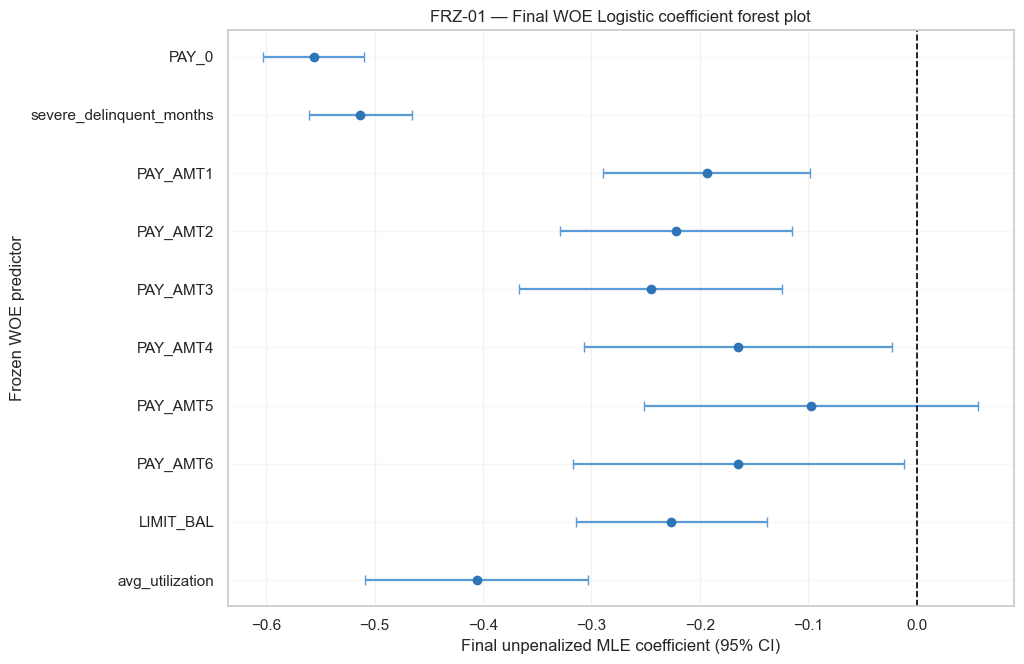

PRESENT — inline final ten-predictor coefficient forest plot with 95% CIs and zero line


In [11]:
plot_table = final_coefficient_table.set_index("Predictor").loc[FINAL_PREDICTORS]
y_positions = np.arange(len(FINAL_PREDICTORS))
coefficients = plot_table["Final Coefficient"].to_numpy()
lower = plot_table["95% CI Lower"].to_numpy()
upper = plot_table["95% CI Upper"].to_numpy()
xerr = np.vstack([coefficients - lower, upper - coefficients])

fig, ax = plt.subplots(figsize=(10.4, 6.8))
ax.errorbar(
    coefficients, y_positions, xerr=xerr, fmt="o", color="#2F75B5",
    ecolor="#5B9BD5", elinewidth=1.6, capsize=3.5, markersize=6,
)
ax.axvline(0, color="black", linestyle="--", linewidth=1.2)
ax.set_yticks(y_positions)
ax.set_yticklabels(FINAL_PREDICTORS)
ax.invert_yaxis()
ax.set_xlabel("Final unpenalized MLE coefficient (95% CI)")
ax.set_ylabel("Frozen WOE predictor")
ax.set_title("FRZ-01 — Final WOE Logistic coefficient forest plot")
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", alpha=0.15)
fig.tight_layout()
plt.show()
plt.close(fig)
FRZ_01_STATUS = "PRESENT — inline final ten-predictor coefficient forest plot with 95% CIs and zero line"
print(FRZ_01_STATUS)


## 9. Final fitted Logistic equation and interpretation

The model form is `logit(P(Default=1)) = β₀ + Σ βⱼ·WOEⱼ`. Because WOE is `ln(DistGood / DistBad)`, higher WOE denotes safer bins. With negative coefficients, moving toward safer WOE values reduces predicted default log-odds while holding the other WOE predictors constant. A one-WOE-unit odds ratio is not a raw business-unit effect, and no causal interpretation is claimed.


In [12]:
equation_terms = [f"{float(params['const']):.9f}"]
for predictor in FINAL_PREDICTORS:
    equation_terms.append(f"{float(params[predictor]):+.9f} × WOE({predictor})")
final_equation = "logit(P(Default=1)) = " + " ".join(equation_terms)
display(Markdown("```text\n" + final_equation + "\n```"))
print("Final apparent Development-Train AUC:", f"{final_apparent_train_auc:.9f}")
print("Final apparent Development-Train KS:", f"{final_apparent_train_ks:.9f}")
print("These are apparent development-sample diagnostics, not unseen-data performance.")


```text
logit(P(Default=1)) = -1.254276175 -0.556303702 × WOE(PAY_0) -0.513060046 × WOE(severe_delinquent_months) -0.193755569 × WOE(PAY_AMT1) -0.222092688 × WOE(PAY_AMT2) -0.245401439 × WOE(PAY_AMT3) -0.165041794 × WOE(PAY_AMT4) -0.097122437 × WOE(PAY_AMT5) -0.164349102 × WOE(PAY_AMT6) -0.226160642 × WOE(LIMIT_BAL) -0.405621158 × WOE(avg_utilization)
```

Final apparent Development-Train AUC: 0.772417098
Final apparent Development-Train KS: 0.430307867
These are apparent development-sample diagnostics, not unseen-data performance.


## 10. Final model-freeze record

Stage 4.5 provides Full-Train candidate-model apparent diagnostics; Stage 4.6 provides five-fold stability and pooled OOF evidence under full-Train-designed bins/predictors; Stage 4.7 records the Human freeze and deterministic Full-Train refit; Stage 5 owns sealed Holdout evaluation and challenger comparison.

Stage 4.6 OOF evidence is not a fully unbiased generalization estimate because supervised bin design and candidate selection used the full Development Train.


In [13]:
coefficient_record = "; ".join(
    f"{name}={float(params[name]):.9f}" for name in ["const", *FINAL_PREDICTORS]
)
final_model_freeze_record = pd.DataFrame({"Frozen value": [
    "Final 10-Variable WOE Logistic",
    "24,000",
    TARGET,
    "18,691",
    "5,309",
    "ln(DistGood / DistBad)",
    "10",
    ", ".join(FINAL_PREDICTORS),
    "Frozen Stage 4.2 / 4.3 definitions; 41 rows",
    "Complete 24,000-row Development Train",
    "Unpenalized maximum likelihood with explicit intercept",
    coefficient_record,
    f"{final_apparent_train_auc:.9f}",
    f"{final_apparent_train_ks:.9f}",
    "0.771230165",
    "0.429462039",
    "SEALED — Stage 5 only",
    "FROZEN after Stage 4.7",
]}, index=[
    "Final model name", "Development sample", "Target", "Good", "Bad", "WOE convention",
    "Final predictor count", "Final predictor list", "Bin definitions", "WOE source",
    "Logistic implementation", "Final coefficients", "Final apparent Train AUC",
    "Final apparent Train KS", "Stage 4.6 pooled OOF AUC", "Stage 4.6 pooled OOF KS",
    "Holdout status", "Model structure status",
])
display(final_model_freeze_record)
MODEL_FREEZE_STATUS = "FROZEN — no predictor/bin/WOE-definition change before Stage 5 absent an explicit Architect reopening for a genuine defect"
print(MODEL_FREEZE_STATUS)


,Frozen value
Final model name,Final 10-Variable WOE Logistic
Development sample,"24,000"
Target,default.payment.next.month
Good,"18,691"
Bad,"5,309"
WOE convention,ln(DistGood / DistBad)
Final predictor count,10
Final predictor list,"PAY_0, severe_delinquent_months, PAY_AMT1, PAY..."
Bin definitions,Frozen Stage 4.2 / 4.3 definitions; 41 rows
WOE source,"Complete 24,000-row Development Train"


FROZEN — no predictor/bin/WOE-definition change before Stage 5 absent an explicit Architect reopening for a genuine defect


## 11. Complete Stage 5 handoff package

The handoff below and the displayed 41-row table together contain the complete frozen primary-model specification. They are not applied to Holdout in this Notebook.


In [14]:
stage5_handoff = pd.DataFrame([
    {"Component": "1. Final predictor list", "Frozen handoff": ", ".join(FINAL_PREDICTORS)},
    {"Component": "2. Exact bin definitions", "Frozen handoff": "BIN_DEFINITIONS above; frozen Stage 4.2/4.3; 41 rows"},
    {"Component": "3. Full-Train WOE mapping", "Frozen handoff": "Complete final_woe_specification table above (41/41 rows)"},
    {"Component": "4. Final intercept", "Frozen handoff": f"{float(params['const']):.12f}"},
    {"Component": "5. Final ten coefficients", "Frozen handoff": "; ".join(f"{p}={float(params[p]):.12f}" for p in FINAL_PREDICTORS)},
    {"Component": "6. WOE convention", "Frozen handoff": "ln(DistGood / DistBad); Good=0, Bad=1"},
    {"Component": "7. Feature definitions", "Frozen handoff": "severe_delinquent_months=sum(PAY_i>=2); avg_utilization=mean(max(BILL_AMTi,0))/LIMIT_BAL; uncapped"},
    {"Component": "8. Train/Test identity", "Frozen handoff": f"Train={train_hash}; Test={test_hash}"},
    {"Component": "9. Holdout sealing", "Frozen handoff": HOLDOUT_SEAL_STATUS},
    {"Component": "10. Stage 4.5 reference", "Frozen handoff": "Apparent AUC=0.772417098; KS=0.430307867; rounded parameter anchors reproduced at atol=1e-9"},
    {"Component": "11. Stage 4.6 reference", "Frozen handoff": "Pooled OOF AUC=0.771230165; pooled OOF KS=0.429462039; full-Train-design limitation applies"},
    {"Component": "12. Stage 4.7 reference", "Frozen handoff": f"Apparent AUC={final_apparent_train_auc:.9f}; KS={final_apparent_train_ks:.9f}"},
])
assert stage5_handoff.shape == (12, 2)
display(stage5_handoff)
STAGE5_HANDOFF_STATUS = "COMPLETE — frozen primary-model specification recorded; not applied to Holdout"
print(STAGE5_HANDOFF_STATUS)


,Component,Frozen handoff
0,1. Final predictor list,"PAY_0, severe_delinquent_months, PAY_AMT1, PAY..."
1,2. Exact bin definitions,BIN_DEFINITIONS above; frozen Stage 4.2/4.3; 4...
2,3. Full-Train WOE mapping,Complete final_woe_specification table above (...
3,4. Final intercept,-1.254276175288
4,5. Final ten coefficients,PAY_0=-0.556303701580; severe_delinquent_month...
5,6. WOE convention,"ln(DistGood / DistBad); Good=0, Bad=1"
6,7. Feature definitions,severe_delinquent_months=sum(PAY_i>=2); avg_ut...
7,8. Train/Test identity,Train=bcb37af63ae7005df78e6140837594b5d650d271...
8,9. Holdout sealing,SEALED — Holdout deleted after row/ID/union/ha...
9,10. Stage 4.5 reference,Apparent AUC=0.772417098; KS=0.430307867; roun...


COMPLETE — frozen primary-model specification recorded; not applied to Holdout


## 12. Final boundaries and machine-verifiable completion summary

All ten predictors are retained. No 10-vs-9 model, feature deletion, re-binning, alternative subset, regularization, class weighting/resampling, cross-validation, OOF prediction, calibration, operational threshold optimization, or Holdout predictive analysis was performed. No Stage 5 execution occurred.


In [15]:
assert HUMAN_FINAL_DECISION == "KEEP ALL 10 PREDICTORS"
assert final_coefficient_table["Final Status"].eq("Retained in Final Logistic").all()
assert final_coefficient_table["Sign Check"].eq("Expected").all()
assert len(final_woe_specification) == 41 and woe_matrix.shape == (24000, 10)
assert FINAL_MODEL_NUMERICALLY_VALID and all(reproduction_checks.values())
assert HOLDOUT_SEAL_STATUS.startswith("SEALED")
assert STAGE5_HANDOFF_STATUS.startswith("COMPLETE")

stage47_results = {
    "project_root": str(project_root),
    "python_executable": sys.executable,
    "python_version": sys.version.split()[0],
    "package_versions": {name: metadata.version(name) for name in [
        "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels"
    ]},
    "raw_rows": 30000,
    "train_rows": len(train_work),
    "test_rows_identity_only": 6000,
    "train_id_sha256": train_hash,
    "test_id_sha256": test_hash,
    "holdout_seal_status": HOLDOUT_SEAL_STATUS,
    "development_good": DEVELOPMENT_GOOD,
    "development_bad": DEVELOPMENT_BAD,
    "development_bad_rate": DEVELOPMENT_BAD_RATE,
    "human_final_decision": HUMAN_FINAL_DECISION,
    "predictors": FINAL_PREDICTORS,
    "pay_amt5_retained": True,
    "pay_amt5_rationale": "weaker conditional strength, stable 5/5 negative direction, close fold/full-Train mean, coherent six-month family, no defensible month-5 cutoff",
    "woe_convention": "ln(DistGood / DistBad)",
    "final_woe_specification_rows": len(final_woe_specification),
    "final_woe_specification": final_woe_specification.to_dict(orient="records"),
    "woe_matrix_shape": list(woe_matrix.shape),
    "woe_missing": woe_missing_count,
    "woe_non_finite": woe_non_finite_count,
    "zero_support_bin_count": zero_support_bin_count,
    "zero_class_bin_count": zero_class_bin_count,
    "smoothing_occurrence_count": smoothing_occurrence_count,
    "model_implementation": "statsmodels.Logit unpenalized maximum likelihood with explicit intercept",
    "substantive_model_count": 1,
    "model_converged": converged,
    "model_iterations": iterations,
    "design_rank": design_rank,
    "warnings": FIT_WARNINGS,
    "final_model_numerically_valid": FINAL_MODEL_NUMERICALLY_VALID,
    "intercept": float(params["const"]),
    "probability_min": float(predicted_probability.min()),
    "probability_max": float(predicted_probability.max()),
    "covariance_min_eigenvalue": covariance_min_eigenvalue,
    "covariance_condition_number": covariance_condition_number,
    "numerical_checks": {name: bool(passed) for name, passed in numerical_checks.items()},
    "coefficient_rows": coefficient_rows,
    "all_ten_negative": bool((final_coefficient_table["Final Coefficient"] < 0).all()),
    "all_ten_retained": bool(final_coefficient_table["Final Status"].eq("Retained in Final Logistic").all()),
    "reproduction_tolerance": REPRODUCTION_TOLERANCE,
    "intercept_absolute_difference": intercept_absolute_difference,
    "max_coefficient_absolute_difference": max_coefficient_absolute_difference,
    "max_parameter_absolute_difference": max_parameter_absolute_difference,
    "final_apparent_train_auc": final_apparent_train_auc,
    "final_apparent_train_ks": final_apparent_train_ks,
    "auc_absolute_difference": auc_absolute_difference,
    "ks_absolute_difference": ks_absolute_difference,
    "ks_diagnostic_threshold": ks_diagnostic_threshold,
    "stage46_pooled_oof_auc": 0.771230165,
    "stage46_pooled_oof_ks": 0.429462039,
    "evidence_synthesis": evidence_synthesis.to_dict(orient="records"),
    "final_equation": final_equation,
    "frz_01_status": FRZ_01_STATUS,
    "model_freeze_status": MODEL_FREEZE_STATUS,
    "stage5_handoff_status": STAGE5_HANDOFF_STATUS,
    "stage5_handoff": stage5_handoff.to_dict(orient="records"),
    "prohibited_work_performed": False,
}

display(pd.DataFrame({"Result": [
    "PASS — frozen Human decision retains all ten predictors including PAY_AMT5",
    "PASS — 41-row Full-Train WOE mapping and aligned 24,000×10 matrix",
    "PASS — exactly one numerically valid final unpenalized MLE Logistic refit",
    "PASS — Stage 4.5 deterministic anchors reproduced within absolute tolerance 1e-9",
    "PASS — model freeze and complete Stage 5 handoff recorded; Holdout remains sealed",
    "PASS — no prohibited analysis",
]}, index=["Decision", "WOE", "Model", "Reproduction", "Freeze/Handoff", "Boundary"]))
print("STAGE47_RESULT_JSON=" + json.dumps(stage47_results, ensure_ascii=False, sort_keys=True))


,Result
Decision,PASS — frozen Human decision retains all ten p...
WOE,PASS — 41-row Full-Train WOE mapping and align...
Model,PASS — exactly one numerically valid final unp...
Reproduction,PASS — Stage 4.5 deterministic anchors reprodu...
Freeze/Handoff,PASS — model freeze and complete Stage 5 hando...
Boundary,PASS — no prohibited analysis


STAGE47_RESULT_JSON={"all_ten_negative": true, "all_ten_retained": true, "auc_absolute_difference": 1.9161305875314838e-10, "coefficient_rows": [{"95% CI Lower": -0.6025884944732375, "95% CI Upper": -0.5100189086866459, "Absolute Refit Difference": 4.2005832145974864e-10, "Expected Sign": "Negative", "Final Coefficient": -0.5563037015799417, "Final Status": "Retained in Final Logistic", "Odds Ratio": 0.5733243299280361, "Predictor": "PAY_0", "Sign Check": "Expected", "Stage 4.5 Reference Coefficient": -0.556303702, "Standard Error": 0.023615124185130114, "p-value": 1.0618671648704898e-122, "z-statistic": -23.557094056284193}, {"95% CI Lower": -0.5608562128288842, "95% CI Upper": -0.465263878611779, "Absolute Refit Difference": 2.7966839954984835e-10, "Expected Sign": "Negative", "Final Coefficient": -0.5130600457203316, "Final Status": "Retained in Final Logistic", "Odds Ratio": 0.5986608435048926, "Predictor": "severe_delinquent_months", "Sign Check": "Expected", "Stage 4.5 Reference 